In [1]:
from __future__ import annotations

import math
import time
import json
import logging
from dataclasses import dataclass, asdict
from typing import Dict, Tuple, Optional, Literal, List

import numpy as np
import pandas as pd

## Step 1: Logging utilities

In [2]:
def setup_logger(level=logging.INFO) -> logging.Logger:
    logger = logging.getLogger("exotic-data-gen")
    if not logger.handlers:
        handler = logging.StreamHandler()
        formatter = logging.Formatter(
            fmt="%(asctime)s | %(levelname)s | %(message)s",
            datefmt="%Y-%m-%d %H:%M:%S",
        )
        handler.setFormatter(formatter)
        logger.addHandler(handler)
    logger.setLevel(level)
    return logger


LOGGER = setup_logger()

## Step 2: Data structures

In [3]:
ModelName = Literal["GBM", "HESTON", "BATES"]
OptionName = Literal["ASIAN_ARITH_CALL", "ASIAN_ARITH_PUT",
                     "BARRIER_UP_AND_OUT_CALL", "BARRIER_DOWN_AND_OUT_PUT",
                     "LOOKBACK_FLOAT_CALL", "LOOKBACK_FLOAT_PUT"]


@dataclass(frozen=True)
class MCConfig:
    n_paths: int = 50_000
    n_steps: int = 252
    antithetic: bool = True
    seed: int = 123
    dtype: str = "float64"  # float32 is faster but less accurate
    batch_paths: int = 25_000  # memory guard


@dataclass(frozen=True)
class ParamRanges:
    # common
    S0: Tuple[float, float] = (50.0, 150.0)
    K: Tuple[float, float] = (50.0, 150.0)
    r: Tuple[float, float] = (0.00, 0.08)
    T: Tuple[float, float] = (0.05, 2.0)  # years

    # GBM
    sigma: Tuple[float, float] = (0.05, 0.90)

    # Heston
    v0: Tuple[float, float] = (0.01, 0.50)
    kappa: Tuple[float, float] = (0.5, 6.0)
    theta: Tuple[float, float] = (0.01, 0.50)
    xi: Tuple[float, float] = (0.10, 2.0)
    rho: Tuple[float, float] = (-0.95, 0.0)

    # Bates jumps (Heston + Merton jumps)
    jump_lambda: Tuple[float, float] = (0.0, 1.0)  # intensity
    jump_mu: Tuple[float, float] = (-0.25, 0.10)   # mean jump size (log)
    jump_delta: Tuple[float, float] = (0.05, 0.50) # std dev jump size (log)

    # Barrier
    barrier_mult: Tuple[float, float] = (0.85, 1.25)  # barrier = barrier_mult * S0


## Step 3: Random parameter sampling

In [4]:
def _u(rng: np.random.Generator, lo: float, hi: float, size=None) -> np.ndarray:
    return rng.uniform(lo, hi, size=size)


def sample_parameters(
    rng: np.random.Generator,
    ranges: ParamRanges,
    model: ModelName,
    option: OptionName,
) -> Dict[str, float]:
    """
    Returns a dict with all required parameters for (model, option).
    Includes common: S0, K, r, T
    """
    S0 = float(_u(rng, *ranges.S0))
    K = float(_u(rng, *ranges.K))
    r = float(_u(rng, *ranges.r))
    T = float(_u(rng, *ranges.T))

    params: Dict[str, float] = {"S0": S0, "K": K, "r": r, "T": T}

    if model == "GBM":
        params["sigma"] = float(_u(rng, *ranges.sigma))

    elif model in ("HESTON", "BATES"):
        # sample raw then apply a basic "sanity" clamp
        v0 = float(_u(rng, *ranges.v0))
        kappa = float(_u(rng, *ranges.kappa))
        theta = float(_u(rng, *ranges.theta))
        xi = float(_u(rng, *ranges.xi))
        rho = float(_u(rng, *ranges.rho))

        # Soft guardrails: keep variance positive-ish and not insane
        v0 = max(v0, 1e-6)
        theta = max(theta, 1e-6)
        xi = max(xi, 1e-6)
        kappa = max(kappa, 1e-6)

        params.update({"v0": v0, "kappa": kappa, "theta": theta, "xi": xi, "rho": rho})

        if model == "BATES":
            params["jump_lambda"] = float(_u(rng, *ranges.jump_lambda))
            params["jump_mu"] = float(_u(rng, *ranges.jump_mu))
            params["jump_delta"] = float(_u(rng, *ranges.jump_delta))

    else:
        raise ValueError(f"Unknown model {model}")

    # Option-specific params
    if "BARRIER" in option:
        barrier_mult = float(_u(rng, *ranges.barrier_mult))
        params["barrier"] = barrier_mult * S0  # relative to spot for realism

    return params

## Step 4: Path simulation (GBM / Heston / Bates)

In [5]:
def simulate_gbm_paths(
    rng: np.random.Generator,
    S0: float,
    r: float,
    sigma: float,
    T: float,
    n_steps: int,
    n_paths: int,
    antithetic: bool,
    dtype=np.float64,
) -> np.ndarray:
    """
    Returns S paths with shape (n_paths, n_steps+1).
    """
    dt = T / n_steps
    nudt = (r - 0.5 * sigma * sigma) * dt
    sigsdt = sigma * math.sqrt(dt)

    half = n_paths // 2 if antithetic else n_paths
    z = rng.standard_normal(size=(half, n_steps)).astype(dtype)

    if antithetic:
        z = np.vstack([z, -z])
        if z.shape[0] < n_paths:  # odd n_paths
            z = np.vstack([z, rng.standard_normal(size=(1, n_steps)).astype(dtype)])

    logS = np.empty((n_paths, n_steps + 1), dtype=dtype)
    logS[:, 0] = math.log(S0)
    logS[:, 1:] = logS[:, [0]] + np.cumsum(nudt + sigsdt * z, axis=1)
    return np.exp(logS)


def simulate_heston_paths_qe(
    rng: np.random.Generator,
    S0: float,
    r: float,
    v0: float,
    kappa: float,
    theta: float,
    xi: float,
    rho: float,
    T: float,
    n_steps: int,
    n_paths: int,
    antithetic: bool,
    dtype=np.float64,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Heston paths using a robust Quadratic-Exponential (QE) scheme for variance.
    Returns (S, v) with shapes:
      S: (n_paths, n_steps+1)
      v: (n_paths, n_steps+1)
    Notes:
      - QE is widely used for stability/positivity.
      - We simulate under risk-neutral drift r.
    """
    dt = T / n_steps
    sqrt_dt = math.sqrt(dt)

    half = n_paths // 2 if antithetic else n_paths
    z1 = rng.standard_normal(size=(half, n_steps)).astype(dtype)
    z2 = rng.standard_normal(size=(half, n_steps)).astype(dtype)

    if antithetic:
        z1 = np.vstack([z1, -z1])
        z2 = np.vstack([z2, -z2])
        if z1.shape[0] < n_paths:
            z1 = np.vstack([z1, rng.standard_normal(size=(1, n_steps)).astype(dtype)])
            z2 = np.vstack([z2, rng.standard_normal(size=(1, n_steps)).astype(dtype)])

    # Correlated Brownian shocks
    wv = z1
    ws = rho * z1 + math.sqrt(max(1.0 - rho * rho, 0.0)) * z2

    v = np.empty((n_paths, n_steps + 1), dtype=dtype)
    S = np.empty((n_paths, n_steps + 1), dtype=dtype)
    v[:, 0] = max(v0, 1e-12)
    S[:, 0] = S0

    # QE parameters
    psi_c = 1.5  # typical threshold

    for t in range(n_steps):
        vt = np.maximum(v[:, t], 0.0)

        m = theta + (vt - theta) * np.exp(-kappa * dt)
        s2 = (vt * xi * xi * np.exp(-kappa * dt) / kappa) * (1.0 - np.exp(-kappa * dt)) \
             + (theta * xi * xi / (2.0 * kappa)) * (1.0 - np.exp(-kappa * dt))**2
        s2 = np.maximum(s2, 1e-18)
        psi = s2 / np.maximum(m * m, 1e-18)

        # Case 1: psi <= psi_c
        idx = psi <= psi_c
        b2 = np.zeros_like(m)
        a = np.zeros_like(m)

        # avoid division issues
        psi_i = np.maximum(psi[idx], 1e-18)
        b2[idx] = 2.0 / psi_i - 1.0 + np.sqrt(2.0 / psi_i) * np.sqrt(np.maximum(2.0 / psi_i - 1.0, 0.0))
        b2[idx] = np.maximum(b2[idx], 1e-18)
        a[idx] = m[idx] / (1.0 + b2[idx])
        v_next = np.empty_like(vt)
        v_next[idx] = a[idx] * (np.sqrt(b2[idx]) + wv[idx, t])**2

        # Case 2: psi > psi_c  (mixture exponential)
        idx2 = ~idx
        p = (psi[idx2] - 1.0) / (psi[idx2] + 1.0)
        p = np.clip(p, 0.0, 1.0)
        beta = (1.0 - p) / np.maximum(m[idx2], 1e-18)
        U = rng.random(size=idx2.sum()).astype(dtype)
        v_next[idx2] = np.where(
            U <= p,
            0.0,
            -np.log((1.0 - p) / np.maximum(1.0 - U, 1e-18)) / np.maximum(beta, 1e-18)
        )

        v[:, t + 1] = np.maximum(v_next, 0.0)

        # Log-Euler for S with integrated variance approx
        v_bar = 0.5 * (vt + v[:, t + 1])
        v_bar = np.maximum(v_bar, 0.0)
        S[:, t + 1] = S[:, t] * np.exp((r - 0.5 * v_bar) * dt + np.sqrt(v_bar) * sqrt_dt * ws[:, t])

    return S, v


def simulate_bates_paths(
    rng: np.random.Generator,
    S0: float,
    r: float,
    v0: float,
    kappa: float,
    theta: float,
    xi: float,
    rho: float,
    jump_lambda: float,
    jump_mu: float,
    jump_delta: float,
    T: float,
    n_steps: int,
    n_paths: int,
    antithetic: bool,
    dtype=np.float64,
) -> np.ndarray:
    """
    Bates = Heston stochastic volatility + Merton lognormal jumps.
    For jumps: d log S includes sum of jumps; drift adjusted by jump compensator.
    """
    dt = T / n_steps

    # First simulate Heston diffusion part
    S, v = simulate_heston_paths_qe(
        rng=rng,
        S0=S0,
        r=r,
        v0=v0,
        kappa=kappa,
        theta=theta,
        xi=xi,
        rho=rho,
        T=T,
        n_steps=n_steps,
        n_paths=n_paths,
        antithetic=antithetic,
        dtype=dtype,
    )

    k = math.exp(jump_mu + 0.5 * jump_delta * jump_delta) - 1.0
    lam = max(jump_lambda, 0.0)

    # Poisson counts per step and path
    N = rng.poisson(lam=lam * dt, size=(n_paths, n_steps)).astype(np.int32)

    jump_log = np.zeros((n_paths, n_steps), dtype=dtype)
    positive = N > 0
    if positive.any():
        means = (N[positive] * jump_mu).astype(dtype)
        stds = (np.sqrt(N[positive]) * jump_delta).astype(dtype)
        jump_log[positive] = rng.normal(loc=means, scale=stds).astype(dtype)

    drift_adj = math.exp(-lam * k * dt)

    # Apply to the path (excluding time 0)
    for t in range(1, n_steps + 1):
        S[:, t] = S[:, t] * (drift_adj * np.exp(jump_log[:, t - 1]))

    return S

## Step 5: Payoff functions (path-dependent)

In [6]:
def payoff_asian_arithmetic(S: np.ndarray, K: float, is_call: bool) -> np.ndarray:
    # arithmetic average over monitoring points excluding S0? Here: include all points
    avg = S.mean(axis=1)
    if is_call:
        return np.maximum(avg - K, 0.0)
    return np.maximum(K - avg, 0.0)


def payoff_barrier_up_and_out_call(S: np.ndarray, K: float, barrier: float) -> np.ndarray:
    # knocked out if path ever >= barrier
    knocked = (S.max(axis=1) >= barrier)
    ST = S[:, -1]
    payoff = np.maximum(ST - K, 0.0)
    payoff[knocked] = 0.0
    return payoff


def payoff_barrier_down_and_out_put(S: np.ndarray, K: float, barrier: float) -> np.ndarray:
    # knocked out if path ever <= barrier
    knocked = (S.min(axis=1) <= barrier)
    ST = S[:, -1]
    payoff = np.maximum(K - ST, 0.0)
    payoff[knocked] = 0.0
    return payoff


def payoff_lookback_floating_call(S: np.ndarray) -> np.ndarray:
    # floating strike: payoff = S_T - min(S)
    ST = S[:, -1]
    m = S.min(axis=1)
    return np.maximum(ST - m, 0.0)


def payoff_lookback_floating_put(S: np.ndarray) -> np.ndarray:
    # payoff = max(S) - S_T
    ST = S[:, -1]
    M = S.max(axis=1)
    return np.maximum(M - ST, 0.0)


def compute_payoff(S: np.ndarray, option: OptionName, params: Dict[str, float]) -> np.ndarray:
    if option == "ASIAN_ARITH_CALL":
        return payoff_asian_arithmetic(S, params["K"], is_call=True)
    if option == "ASIAN_ARITH_PUT":
        return payoff_asian_arithmetic(S, params["K"], is_call=False)

    if option == "BARRIER_UP_AND_OUT_CALL":
        return payoff_barrier_up_and_out_call(S, params["K"], params["barrier"])
    if option == "BARRIER_DOWN_AND_OUT_PUT":
        return payoff_barrier_down_and_out_put(S, params["K"], params["barrier"])

    if option == "LOOKBACK_FLOAT_CALL":
        return payoff_lookback_floating_call(S)
    if option == "LOOKBACK_FLOAT_PUT":
        return payoff_lookback_floating_put(S)

    raise ValueError(f"Unknown option {option}")

## Step 6: Monte Carlo pricing (batched)

In [7]:
def mc_price(
    rng: np.random.Generator,
    model: ModelName,
    option: OptionName,
    params: Dict[str, float],
    cfg: MCConfig,
) -> Tuple[float, float]:
    """
    Returns (price, std_error).
    Uses batching to avoid huge memory.
    """
    n_paths = cfg.n_paths
    n_steps = cfg.n_steps
    antithetic = cfg.antithetic
    dtype = np.float32 if cfg.dtype == "float32" else np.float64

    S0, r, T = params["S0"], params["r"], params["T"]
    disc = math.exp(-r * T)

    payoffs_all = []
    remaining = n_paths
    while remaining > 0:
        b = min(cfg.batch_paths, remaining)
        remaining -= b

        # NOTE: antithetic works best with even b, but we keep it simple & robust.
        if model == "GBM":
            S = simulate_gbm_paths(
                rng, S0=S0, r=r, sigma=params["sigma"], T=T,
                n_steps=n_steps, n_paths=b, antithetic=antithetic, dtype=dtype
            )

        elif model == "HESTON":
            S, _v = simulate_heston_paths_qe(
                rng, S0=S0, r=r,
                v0=params["v0"], kappa=params["kappa"], theta=params["theta"],
                xi=params["xi"], rho=params["rho"],
                T=T, n_steps=n_steps, n_paths=b, antithetic=antithetic, dtype=dtype
            )

        elif model == "BATES":
            S = simulate_bates_paths(
                rng, S0=S0, r=r,
                v0=params["v0"], kappa=params["kappa"], theta=params["theta"],
                xi=params["xi"], rho=params["rho"],
                jump_lambda=params["jump_lambda"], jump_mu=params["jump_mu"], jump_delta=params["jump_delta"],
                T=T, n_steps=n_steps, n_paths=b, antithetic=antithetic, dtype=dtype
            )
        else:
            raise ValueError(f"Unknown model {model}")

        payoff = compute_payoff(S, option, params)
        payoffs_all.append(payoff.astype(np.float64))

    payoff_vec = np.concatenate(payoffs_all, axis=0)
    price = disc * float(payoff_vec.mean())
    # standard error of discounted payoff mean:
    stderr = disc * float(payoff_vec.std(ddof=1) / math.sqrt(payoff_vec.shape[0]))
    return price, stderr

## Step 7: Dataset generation & saving

In [8]:
def generate_dataset(
    n_samples: int,
    models: List[ModelName],
    options: List[OptionName],
    ranges: ParamRanges,
    cfg: MCConfig,
    out_path: str = "exotic_mc_dataset.parquet",
) -> pd.DataFrame:
    """
    Generates a dataset of size n_samples (each row is one priced contract).
    Randomly picks model and option for each row from provided lists.
    """
    t0 = time.time()
    rng = np.random.default_rng(cfg.seed)

    rows = []
    for i in range(n_samples):
        model = models[int(rng.integers(0, len(models)))]
        option = options[int(rng.integers(0, len(options)))]

        params = sample_parameters(rng, ranges, model=model, option=option)
        price, stderr = mc_price(rng, model, option, params, cfg)

        row = {
            "model": model,
            "option": option,
            "price": price,
            "stderr": stderr,
            # Common
            "S0": params["S0"],
            "K": params["K"],
            "r": params["r"],
            "T": params["T"],
            # GBM
            "sigma": params.get("sigma", np.nan),
            # Heston/Bates
            "v0": params.get("v0", np.nan),
            "kappa": params.get("kappa", np.nan),
            "theta": params.get("theta", np.nan),
            "xi": params.get("xi", np.nan),
            "rho": params.get("rho", np.nan),
            # Bates jumps
            "jump_lambda": params.get("jump_lambda", np.nan),
            "jump_mu": params.get("jump_mu", np.nan),
            "jump_delta": params.get("jump_delta", np.nan),
            # Barrier
            "barrier": params.get("barrier", np.nan),
        }
        rows.append(row)

        if (i + 1) % max(1, n_samples // 10) == 0:
            LOGGER.info(f"Generated {i+1}/{n_samples} samples...")

    df = pd.DataFrame(rows)

    # Save
    df.to_parquet(out_path, index=False)
    meta = {
        "generated_at_unix": time.time(),
        "n_samples": n_samples,
        "models": models,
        "options": options,
        "mc_config": asdict(cfg),
        "param_ranges": asdict(ranges),
    }
    with open(out_path.replace(".parquet", "_meta.json"), "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)

    LOGGER.info(f"Saved dataset: {out_path}")
    LOGGER.info(f"Saved metadata: {out_path.replace('.parquet', '_meta.json')}")
    LOGGER.info(f"Total time: {time.time() - t0:.2f} seconds")
    return df

## Step 7: Dataset generation & saving

In [10]:
if __name__ == "__main__":
    MODELS: List[ModelName] = ["GBM", "HESTON", "BATES"]
    OPTIONS: List[OptionName] = [
        "ASIAN_ARITH_CALL",
        "ASIAN_ARITH_PUT",
        "BARRIER_UP_AND_OUT_CALL",
        "BARRIER_DOWN_AND_OUT_PUT",
        "LOOKBACK_FLOAT_CALL",
        "LOOKBACK_FLOAT_PUT",
    ]

    ranges = ParamRanges()
    cfg = MCConfig(
        n_paths=30_000,     
        n_steps=252,        
        antithetic=True,
        seed=42,
        dtype="float64",
        batch_paths=15_000,
    )

    df = generate_dataset(
        n_samples=100,      
        models=MODELS,
        options=OPTIONS,
        ranges=ranges,
        cfg=cfg,
        out_path="exotic_mc_dataset.parquet",
    )

    print(df.head())

2026-02-01 18:26:56 | INFO | Generated 10/100 samples...
2026-02-01 18:27:09 | INFO | Generated 20/100 samples...
2026-02-01 18:27:21 | INFO | Generated 30/100 samples...
2026-02-01 18:27:35 | INFO | Generated 40/100 samples...
2026-02-01 18:27:41 | INFO | Generated 50/100 samples...
2026-02-01 18:27:59 | INFO | Generated 60/100 samples...
2026-02-01 18:28:07 | INFO | Generated 70/100 samples...
2026-02-01 18:28:13 | INFO | Generated 80/100 samples...
2026-02-01 18:28:22 | INFO | Generated 90/100 samples...
2026-02-01 18:28:29 | INFO | Generated 100/100 samples...
2026-02-01 18:28:31 | INFO | Saved dataset: exotic_mc_dataset.parquet
2026-02-01 18:28:31 | INFO | Saved metadata: exotic_mc_dataset_meta.json
2026-02-01 18:28:31 | INFO | Total time: 106.93 seconds


    model                    option      price    stderr          S0  \
0     GBM       LOOKBACK_FLOAT_CALL  27.298629  0.181989   93.887844   
1     GBM       LOOKBACK_FLOAT_CALL  37.798973  0.245171  133.264199   
2   BATES  BARRIER_DOWN_AND_OUT_PUT   0.000000  0.000000  114.000253   
3  HESTON           ASIAN_ARITH_PUT  49.312463  0.182873  102.485076   
4   BATES          ASIAN_ARITH_CALL  19.756899  0.183135   97.171672   

            K         r         T     sigma        v0     kappa     theta  \
0  135.859792  0.055789  0.233646  0.879279       NaN       NaN       NaN   
1  113.865345  0.047478  0.414686  0.636791       NaN       NaN       NaN   
2   93.627851  0.044818  1.263542       NaN  0.275776  2.774970  0.113014   
3  147.685871  0.027255  1.389348       NaN  0.494418  2.718432  0.364860   
4   87.049211  0.052065  1.098681       NaN  0.464715  2.603416  0.375134   

         xi       rho  jump_lambda   jump_mu  jump_delta     barrier  
0       NaN       NaN          Na

## Veranschaulichung

In [8]:
import pandas as pd
import numpy as np

# Dataset laden
df = pd.read_parquet("exotic_mc_dataset_1.parquet")

# Beispiel: Barrier Option auswählen
sample = df[
    (df["option"] == "BARRIER_UP_AND_OUT_CALL") &
    (df["model"] == "BATES")
].iloc[0]

print(sample)

model                            BATES
option         BARRIER_UP_AND_OUT_CALL
price                         0.021399
stderr                        0.002744
S0                          148.872831
K                            136.96376
r                             0.056302
T                             1.474109
sigma                              NaN
v0                            0.334268
kappa                         1.280888
theta                         0.445425
xi                            0.794766
rho                          -0.918054
jump_lambda                   0.969186
jump_mu                      -0.037182
jump_delta                    0.440941
barrier                     158.686117
Name: 5, dtype: object


In [9]:
import matplotlib.pyplot as plt

def visualize_contract_from_row(row, n_paths=300, n_steps=252):
    rng = np.random.default_rng(999)

    model = row["model"]

    params = {
        "S0": row["S0"],
        "K": row["K"],
        "r": row["r"],
        "T": row["T"],
        "sigma": row.get("sigma"),
        "v0": row.get("v0"),
        "kappa": row.get("kappa"),
        "theta": row.get("theta"),
        "xi": row.get("xi"),
        "rho": row.get("rho"),
        "jump_lambda": row.get("jump_lambda"),
        "jump_mu": row.get("jump_mu"),
        "jump_delta": row.get("jump_delta"),
        "barrier": row.get("barrier"),
    }

    # Nur wenige Pfade simulieren
    if model == "GBM":
        S = simulate_gbm_paths(
            rng,
            S0=params["S0"],
            r=params["r"],
            sigma=params["sigma"],
            T=params["T"],
            n_steps=n_steps,
            n_paths=n_paths,
            antithetic=True
        )

    elif model == "HESTON":
        S, _ = simulate_heston_paths_qe(
            rng,
            S0=params["S0"],
            r=params["r"],
            v0=params["v0"],
            kappa=params["kappa"],
            theta=params["theta"],
            xi=params["xi"],
            rho=params["rho"],
            T=params["T"],
            n_steps=n_steps,
            n_paths=n_paths,
            antithetic=True
        )

    elif model == "BATES":
        S = simulate_bates_paths(
            rng,
            S0=params["S0"],
            r=params["r"],
            v0=params["v0"],
            kappa=params["kappa"],
            theta=params["theta"],
            xi=params["xi"],
            rho=params["rho"],
            jump_lambda=params["jump_lambda"],
            jump_mu=params["jump_mu"],
            jump_delta=params["jump_delta"],
            T=params["T"],
            n_steps=n_steps,
            n_paths=n_paths,
            antithetic=True
        )

    # Barrier Visualisierung
    barrier = params["barrier"]
    knocked = (S.max(axis=1) >= barrier)

    plt.figure(figsize=(10,6))

    for i in range(min(40, n_paths)):
        color = "red" if knocked[i] else "blue"
        plt.plot(S[i], color=color, alpha=0.6)

    plt.axhline(barrier, linestyle="--")
    plt.title(f"{model} Barrier Option\nRed = Knocked Out")
    plt.xlabel("Time Step")
    plt.ylabel("Asset Price")
    plt.show()

    print(f"Knock-out probability (sample estimate): {knocked.mean():.3f}")

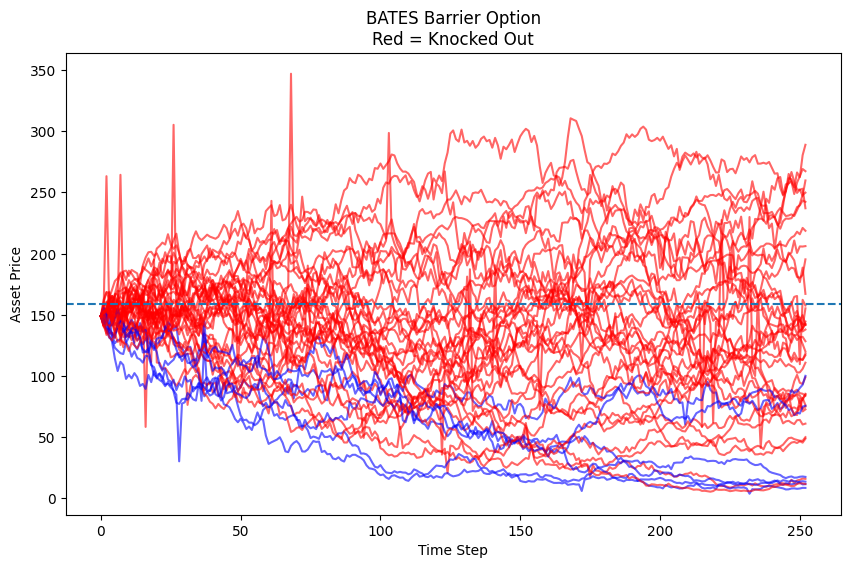

Knock-out probability (sample estimate): 0.870


In [10]:
visualize_contract_from_row(sample)